weights = [0.4, 0.4] bias = -0.9 accuracy = 0.5 predictions = [0 0 0 0 0 0]
weights = [1.0, 0.8] bias = -1.0 accuracy = 1.0 predictions = [0 0 0 1 1 1]
weights = [1.0, 1.0] bias = -1.25 accuracy = 1.0 predictions = [0 0 0 1 1 1]
Trained weights: [0.075 0.1  ] bias: -0.1
Final predictions: [0 0 0 1 1 1] accuracy: 1.0


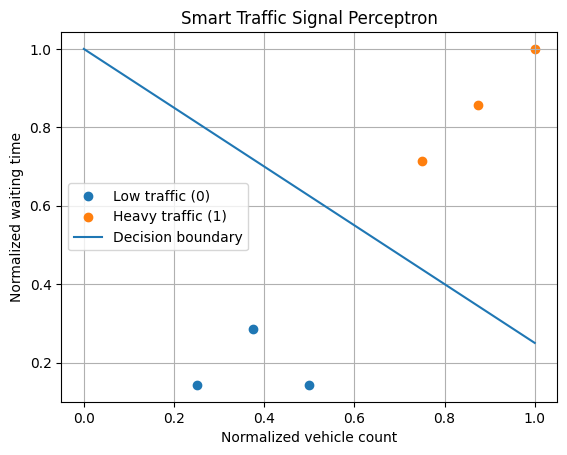

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Features: [vehicle count, average waiting time]
X = np.array([[2, 1], [3, 2], [4, 1], [6, 5], [7, 6], [8, 7]], dtype=float)
y = np.array([0, 0, 0, 1, 1, 1])  # 0 = low, 1 = heavy
Xn = X / X.max(axis=0)  # scale features to a similar range

def predict(X, w, b):
    return (X @ w + b >= 0).astype(int)

# Compare parameter choices
settings = [([0.4, 0.4], -0.9), ([1.0, 0.8], -1.0), ([1.0, 1.0], -1.25)]
for w, b in settings:
    pred = predict(Xn, np.array(w), b)
    print("weights =", w, "bias =", b,
          "accuracy =", round(np.mean(pred == y), 2), "predictions =", pred)

# Use a simple perceptron learning rule
w = np.zeros(2)
b = 0.0
lr = 0.1
for epoch in range(30):
    for xi, target in zip(Xn, y):
        pred = int(xi @ w + b >= 0)
        error = target - pred
        w += lr * error * xi
        b += lr * error

pred = predict(Xn, w, b)
print("Trained weights:", w, "bias:", b)
print("Final predictions:", pred, "accuracy:", np.mean(pred == y))

plt.scatter(Xn[y == 0, 0], Xn[y == 0, 1], label="Low traffic (0)")
plt.scatter(Xn[y == 1, 0], Xn[y == 1, 1], label="Heavy traffic (1)")
xx = np.linspace(0, 1, 100)
if abs(w[1]) > 1e-8:
    yy = -(w[0] * xx + b) / w[1]
    plt.plot(xx, yy, label="Decision boundary")
plt.xlabel("Normalized vehicle count")
plt.ylabel("Normalized waiting time")
plt.title("Smart Traffic Signal Perceptron")
plt.legend()
plt.grid(True)
plt.show()
